# EEG motor imagery: xdflow vs. plain scikit-learn

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/general-sense/xdflow/blob/main/examples/notebooks/eeg_motor_imagery.ipynb)

Decode imagined left- vs right-fist movement from public EEG (the PhysioNet EEG Motor Movement/Imagery dataset,
subjects 1-5) with the classic band-pass -> CSP -> LDA model, written once with xdflow and once with plain NumPy and
scikit-learn. The model is asked two questions: does it decode a person's new trials after calibration on their own
trials (within subject), and does a model trained on other people decode someone it has never seen (across subjects)?
You'll see that with identical preprocessing, model and folds the two versions produce the same scores, while xdflow
keeps labels and subjects attached and decides which steps are refit per fold. You'll also see a common shortcut, fitting CSP on all
trials before cross-validating the classifier, report 0.96 within-subject accuracy. That is inflated by leakage; the correct estimate is 0.64.

The first run downloads 38.6 MB of EDF files from PhysioNet, which can be slow (over 10 minutes when this example was
written). After that the analysis takes about 15 s on a laptop. The full write-up is the [EEG Motor Imagery tutorial](https://xdflow.readthedocs.io/en/latest/tutorials/eeg-motor-imagery/).

In [ ]:
# Install xdflow with its MNE extra (MNE reads the EDF files and provides CSP).
%pip install -q "xdflow[mne]>=0.3"

## Settings

The epoch, window, band and number of CSP components below are the ones the tutorial uses.

In [1]:
import mne
import numpy as np
import pandas as pd
import xarray as xr
from mne.datasets import eegbci

mne.set_log_level("ERROR")

SUBJECTS = [1, 2, 3, 4, 5]  # the last one is the cross-subject holdout
HOLDOUT_SUBJECT = SUBJECTS[-1]
if len(SUBJECTS) < 3:
    raise ValueError("Need at least 3 subjects: leave-one-subject-out on >= 2, plus one holdout subject.")

RUNS = (4, 8, 12)  # imagery runs; annotation T1 = left fist, T2 = right fist
FS = 160  # Hz; the loader rejects recordings at any other rate
EPOCH = (-1.0, 4.5)  # s around the cue; margins absorb filter edge effects
WINDOW = (0.5, 4.0)  # s after the cue that the model sees
BAND = (8.0, 30.0)  # Hz, mu + beta rhythms, which desynchronize over the contralateral motor cortex
N_CSP = 6
SEED = 0

## 1. Loading the data

The [dataset](https://physionet.org/content/eegmmidb/1.0.0/) has 64-channel EEG sampled at 160 Hz. In runs 4, 8 and
12, a cue tells the subject to imagine opening and closing the left fist (`T1`) or the right fist (`T2`) for about
4 s. The loader epochs each run with MNE and stacks the runs into one `DataArray` with `trial`, `channel` and `time`
dimensions, plus three trial-level coordinates: `label`, `subject` and `run`.

In [2]:
from xdflow import from_mne_epochs


def load_motor_imagery(subjects: list[int], data_dir: str | None = None) -> xr.DataArray:
    """Epoch the imagery runs into (trial, channel, time) with label/subject/run coordinates."""
    pieces = []
    for subject in subjects:
        for run in RUNS:
            [path] = eegbci.load_data(subject, [run], path=data_dir, update_path=False)
            raw = mne.io.read_raw_edf(path, preload=True)
            eegbci.standardize(raw)  # canonical 10-20 channel names
            if raw.info["sfreq"] != FS:
                raise ValueError(f"S{subject:03d}R{run:02d}: expected {FS} Hz, got {raw.info['sfreq']} Hz")
            events, _ = mne.events_from_annotations(raw, event_id={"T1": 1, "T2": 2})
            epochs = mne.Epochs(raw, events, {"left": 1, "right": 2}, *EPOCH, baseline=None, preload=True)
            # labels come from the event names; subject and run become trial coordinates
            pieces.append(from_mne_epochs(epochs, subject=subject, run=run).data)
    # join="exact" fails loudly if channel names or time stamps differ between recordings.
    data = xr.concat(pieces, dim="trial", join="exact")
    return data.assign_coords(trial=np.arange(data.sizes["trial"]))

In [3]:
data = load_motor_imagery(SUBJECTS)  # downloads into ~/mne_data on the first run
print(dict(data.sizes))
data["label"].to_series().groupby(data["subject"].values).value_counts().unstack().rename_axis("subject")

{'trial': 216, 'channel': 64, 'time': 881}


label,left,right
subject,,
1,23,22
2,21,21
3,23,22
4,21,21
5,21,21


## 2. CSP as a stateful step

[Common spatial patterns](https://en.wikipedia.org/wiki/Common_spatial_pattern) (CSP) learns spatial filters that
separate the two classes by variance. It uses the labels to learn its filters, so it must only ever see training
trials. xdflow's `CSPTransform` wraps MNE's CSP and declares `is_stateful = True`, so validators refit it inside every
training fold. (A transform like it is about 30 lines to write yourself; see
[Writing Custom Transforms](https://xdflow.readthedocs.io/en/latest/guides/writing-transforms/).)

In [4]:
from mne.decoding import CSP  # used directly by the plain scikit-learn version below

from xdflow.core import DataContainer, Transform
from xdflow.transforms.csp import CSPTransform

## 3. One pipeline from epochs to predictions

Band-pass to 8-30 Hz, crop to 0.5-4.0 s after the cue, then CSP and linear discriminant analysis (LDA). For
within-subject decoding, `GroupApplyTransform` wraps CSP+LDA so each value of the `subject` coordinate gets its own
model.

Validators split this pipeline at its first stateful step: the band-pass filter and the crop run once on all trials,
and CSP and LDA are cloned and refit on each training fold.

In [5]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from xdflow.composite import GroupApplyTransform, Pipeline
from xdflow.transforms.basic_transforms import CropTimeTransform
from xdflow.transforms.sklearn_transform import SKLearnPredictor
from xdflow.transforms.spectral import BandpassFilterTransform


def build_pipeline(per_subject: bool = False) -> Pipeline:
    model: Transform = Pipeline(
        name="csp_lda",
        steps=[
            ("csp", CSPTransform(n_components=N_CSP)),  # stateful: refit on every training fold
            ("lda", SKLearnPredictor(LinearDiscriminantAnalysis, sample_dim="trial", target_coord="label")),
        ],
    )
    if per_subject:  # a separate CSP+LDA for each value of the `subject` coordinate
        model = GroupApplyTransform(group_coord="subject", transform_template=model)
    return Pipeline(
        name="motor_imagery",
        steps=[
            ("bandpass", BandpassFilterTransform(*BAND, fs=FS)),  # stateless: runs once, before the folds
            ("crop", CropTimeTransform(*WINDOW)),  # stateless: label-based slice of the time coord
            ("model", model),
        ],
    )


container = DataContainer(data)

## 4. Within-subject validation

`GroupedKFoldValidator` runs per-subject models with folds stratified by subject × label, and holds out 20% of every
subject's trials until the end.

> **`GroupedKFoldValidator` is not sklearn's `GroupKFold`.** sklearn's `GroupKFold` keeps each group (here, each
> subject) entirely in one fold. `GroupedKFoldValidator(group_coord="subject")` does the opposite: it stratifies folds
> by subject × label, so every subject appears in every training fold. That is the right design for within-subject
> models. To keep subjects apart, use `LeaveGroupOutValidator` (next section).

In [6]:
from xdflow.cv import GroupedKFoldValidator, LeaveGroupOutValidator

within = GroupedKFoldValidator(
    n_splits=5, test_size=0.2, group_coord="subject", scoring="accuracy", random_state=SEED, verbose=False
)
within.set_pipeline(build_pipeline(per_subject=True))
within_cv = within.cross_validate(container)
within_holdout = within.score_on_holdout(container)
print(f"Within subject: 5-fold CV accuracy {within_cv:.3f}, 20% holdout accuracy {within_holdout:.3f}")

Within subject: 5-fold CV accuracy 0.645, 20% holdout accuracy 0.614


## 5. Cross-subject validation

`LeaveGroupOutValidator` runs leave-one-subject-out CV on the other subjects, then scores the held-out subject, who is
never seen in training.

In [7]:
across = LeaveGroupOutValidator(
    group_coord="subject", test_group_ids=[HOLDOUT_SUBJECT], scoring="accuracy", verbose=False
)
across.set_pipeline(build_pipeline())
across_cv = across.cross_validate(container)
across_holdout = across.score_on_holdout(container)
print(
    f"Across subjects: LOSO CV accuracy {across_cv:.3f} (excl. S{HOLDOUT_SUBJECT}), "
    f"holdout S{HOLDOUT_SUBJECT} accuracy {across_holdout:.3f}"
)

Across subjects: LOSO CV accuracy 0.563 (excl. S5), holdout S5 accuracy 0.500


## 6. Per-subject accuracy from out-of-fold predictions

Out-of-fold predictions keep their trial coordinates (`label`, `subject`, `run`, plus a `fold` coordinate), so
per-subject cross-validation accuracy is an xarray `groupby`, with no index arrays to carry around.

In [8]:
predicted = within.oof_predictions_container_.data
per_subject = pd.DataFrame(
    {
        "cv_accuracy": (predicted == predicted["label"]).groupby("subject").mean().to_series(),
        "n_trials": predicted["subject"].to_series().value_counts().sort_index(),
    }
)
per_subject.round(2)

,cv_accuracy,n_trials
subject,,
1,0.77,35
2,0.91,34
3,0.57,35
4,0.50,34
5,0.47,34


## 7. The same analysis in plain NumPy + scikit-learn

A plain workflow builds `X`, `y` and `subjects` in the loading loop. Here they are taken from the same `DataArray`, so
both versions see exactly the same trials. This version is correct and short: CSP sits inside the sklearn `Pipeline`,
so `cross_val_score` refits it per fold. The bookkeeping is all positional: `X`, `y` and `subjects` must stay in the
same order through every mask, `axis=-1` must be time, the crop is a boolean mask over a separate `times` array, a
per-subject model is a Python loop, and the filter and crop live outside the sklearn `Pipeline`.

In [9]:
from scipy.signal import butter, filtfilt
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X, y, subjects, times = data.values, data["label"].values, data["subject"].values, data["time"].values
b, a = butter(4, BAND, btype="bandpass", fs=FS)
X = filtfilt(b, a, X, axis=-1)  # axis -1 must be time
X = X[..., (times >= WINDOW[0]) & (times <= WINDOW[1])]


def model():
    return make_pipeline(CSP(n_components=N_CSP, log=True), LinearDiscriminantAnalysis())


kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sk_within_cv = np.mean(
    [cross_val_score(model(), X[subjects == s], y[subjects == s], cv=kfold).mean() for s in np.unique(subjects)]
)

train = subjects != HOLDOUT_SUBJECT
sk_across_cv = cross_val_score(model(), X[train], y[train], groups=subjects[train], cv=LeaveOneGroupOut()).mean()
sk_across_holdout = model().fit(X[train], y[train]).score(X[~train], y[~train])
print(f"sklearn: within CV {sk_within_cv:.3f}, LOSO CV {sk_across_cv:.3f}, holdout {sk_across_holdout:.3f}")

sklearn: within CV 0.636, LOSO CV 0.563, holdout 0.500


### A shortcut with a hidden trap

CSP is the expensive, label-dependent step. A tempting shortcut is to compute CSP features once on all trials, "to
save time", and then cross-validate only the classifier. The code runs cleanly, but CSP has already seen the
validation trials and their labels, so the spatial filters are tuned to the trials being scored.

In [10]:
# The mistake: CSP is fit on all trials, including every validation fold.
leaky_within = []
for s in np.unique(subjects):
    features = CSP(n_components=N_CSP, log=True).fit_transform(X[subjects == s], y[subjects == s])
    leaky_within.append(cross_val_score(LinearDiscriminantAnalysis(), features, y[subjects == s], cv=kfold).mean())
leaky_within_cv = np.mean(leaky_within)

features = CSP(n_components=N_CSP, log=True).fit_transform(X[train], y[train])
leaky_across_cv = cross_val_score(
    LinearDiscriminantAnalysis(), features, y[train], groups=subjects[train], cv=LeaveOneGroupOut()
).mean()
print(f"sklearn, CSP fit before CV: within CV {leaky_within_cv:.3f}, LOSO CV {leaky_across_cv:.3f}")

sklearn, CSP fit before CV: within CV 0.962, LOSO CV 0.775


## 8. Results

In [11]:
results = pd.DataFrame(
    [
        (within_cv, sk_within_cv, leaky_within_cv),
        (within_holdout, np.nan, np.nan),
        (across_cv, sk_across_cv, leaky_across_cv),
        (across_holdout, sk_across_holdout, np.nan),
    ],
    index=[
        "Within subject, 5-fold CV",
        "Within subject, 20% holdout",
        f"Across subjects, LOSO CV (excl. S{HOLDOUT_SUBJECT})",
        f"Across subjects, holdout S{HOLDOUT_SUBJECT}",
    ],
    columns=["xdflow", "sklearn", "sklearn, CSP fit before CV"],
).rename_axis("Accuracy (chance = 0.50)")
results.map(lambda score: "-" if np.isnan(score) else f"{score:.3f}")

,xdflow,sklearn,"sklearn, CSP fit before CV"
Accuracy (chance = 0.50),,,
"Within subject, 5-fold CV",0.645,0.636,0.962
"Within subject, 20% holdout",0.614,-,-
"Across subjects, LOSO CV (excl. S5)",0.563,0.563,0.775
"Across subjects, holdout S5",0.500,0.500,-


The left panel compares the cross-validated scores; the right panel breaks the xdflow within-subject CV accuracy down
by subject. The dotted ticks mark the 97.5th percentile of chance accuracy for each subject's number of out-of-fold
trials.

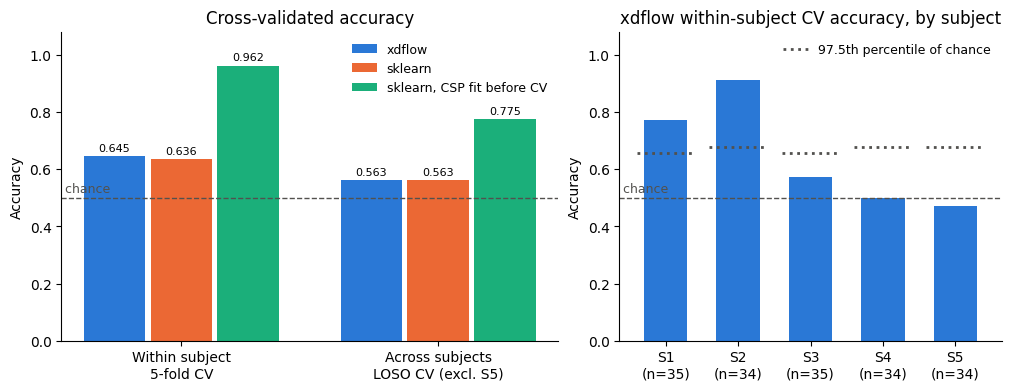

In [12]:
import matplotlib.pyplot as plt
from scipy.stats import binom

versions = {"xdflow": "#2a78d6", "sklearn": "#eb6834", "sklearn, CSP fit before CV": "#1baf7a"}
cv_rows = results.iloc[[0, 2]]
fig, (ax_cv, ax_subj) = plt.subplots(
    1, 2, figsize=(10, 3.8), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1]}
)

positions = np.arange(len(cv_rows))
width = 0.26
for i, (version, color) in enumerate(versions.items()):
    bars = ax_cv.bar(positions + (i - 1) * width, cv_rows[version], width * 0.92, color=color, label=version)
    ax_cv.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
ax_cv.set_xticks(positions, ["Within subject\n5-fold CV", f"Across subjects\nLOSO CV (excl. S{HOLDOUT_SUBJECT})"])
ax_cv.set_title("Cross-validated accuracy")
ax_cv.legend(frameon=False, loc="upper right", fontsize=9)

subject_ids = per_subject.index.to_numpy()
ax_subj.bar(subject_ids, per_subject["cv_accuracy"], 0.6, color=versions["xdflow"])
chance_975 = binom.ppf(0.975, per_subject["n_trials"], 0.5) / per_subject["n_trials"]
ax_subj.hlines(
    chance_975,
    subject_ids - 0.4,
    subject_ids + 0.4,
    colors="#52514e",
    linestyles=":",
    linewidth=2,
    label="97.5th percentile of chance",
)
ax_subj.legend(frameon=False, loc="upper right", fontsize=9)
ax_subj.set_xticks(subject_ids, [f"S{s}\n(n={n})" for s, n in per_subject["n_trials"].items()])
ax_subj.set_title("xdflow within-subject CV accuracy, by subject")

for ax in (ax_cv, ax_subj):
    ax.axhline(0.5, color="#52514e", linestyle="--", linewidth=1)
    ax.text(ax.get_xlim()[0], 0.51, " chance", color="#52514e", fontsize=9, va="bottom")
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Accuracy")
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## What this shows

- **Same model, same numbers.** Across subjects the two versions give identical scores (0.563 and 0.500); within
  subject they are within 0.01 (0.645 and 0.636).
- **The shortcut inflates accuracy dramatically.** Fitting CSP on all trials before cross-validating reports 0.962
  within subject and 0.775 across subjects, against 0.64 and 0.56 with CSP fit inside each fold. In xdflow, CSP is a
  stateful step, so it is always refit inside each fold.
- **Per-subject results come straight from the data:** a `groupby` on the out-of-fold predictions.

## What xdflow buys you here

- **Metadata stays attached.** `label`, `subject` and `run` follow every trial through filtering, cropping, CSP and
  prediction, so per-subject results are a `groupby`.
- **Splits are named.** `group_coord="subject"` and `test_group_ids=[5]`, no `groups` array to keep aligned.
- **Per-group models are one wrapper:** `GroupApplyTransform`.
- **Safe and fast at once.** Stateless steps run once and stateful steps are refit per fold, so the correct version
  is also the fast one, and the precompute shortcut has no reason to exist.
- **Leak safety is declared, not remembered.** Built-in transforms declare whether they learn, and the ones that can
  pool statistics across trials warn when they do; your own transforms declare it with `is_stateful = True`.
- **Your model stays your model.** Like for like the scores are identical, and an existing scikit-learn pipeline can
  be wrapped with `SKLearnPredictor.from_estimator`.

## Next steps

- The [EEG Motor Imagery tutorial](https://xdflow.readthedocs.io/en/latest/tutorials/eeg-motor-imagery/) has the full discussion.
- [Execution Model](https://xdflow.readthedocs.io/en/latest/concepts/execution/) describes the stateless/stateful split boundary in detail.
- [Hyperparameter Tuning](https://xdflow.readthedocs.io/en/latest/tutorials/tuning/) shows how to select the window, band or number of CSP components
  inside the validation loop instead of by hand.